<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion18/sesion18_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 18 · Rate Limiting, Throttling y Prevención de Abuso

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Cómo evitas que un script sature tu API? = Implementando Rate Limiting, es decir, limitando el número de peticiones que un mismo cliente puede realizar en un periodo de tiempo determinado. Cuando el límite se supera, la API responde con HTTP 429 (Too Many Requests) e indica mediante Retry-After cuánto tiempo debe esperar el cliente antes de volver a intentarlo. Esto protege el servicio para todos los usuarios sin bloquear permanentemente al cliente.

---

## 🖥️ Así se verá el resultado final

```http
GET /api/recurso   -> 200 OK   (1.ª petición)
GET /api/recurso   -> 200 OK   (2.ª petición)
GET /api/recurso   -> 200 OK   (3.ª petición)
GET /api/recurso   -> 429 Too Many Requests
Retry-After: 60
{"error":"límite de peticiones alcanzado"}
```

_El límite protege el servicio para todos; no es un castigo al cliente._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Implementar un límite de peticiones por cliente.
- Responder 429 con Retry-After.
- Explicar la diferencia entre limitar y bloquear.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] Primera petición permitida → HTTP 200
- [ ] Segunda petición permitida → HTTP 200
- [ ] Tercera petición permitida → HTTP 200
- [ ] La cuarta petición se limita → HTTP 429

## 🧩 El reto

Implementa un límite de tres peticiones por minuto por cliente y responde 429 cuando se exceda.

**Requisitos del contrato**

- GET /api/recurso permite tres peticiones por cliente en una ventana de 60 segundos.
- La cuarta petición responde 429.
- La respuesta 429 incluye Retry-After.
- Las tres primeras responden 200 con un JSON simple.
- El contador se reinicia al iniciar la aplicación.

> **Pista conceptual:** El cliente se identifica por IP o por token. Un contador global castiga a todos; un contador por cliente protege a todos.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion18.md` con el cálculo de la ventana.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [1]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [3]:
%%writefile app.py
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse

app = FastAPI(title="Tu límite de peticiones se verá así")

# Contador por cliente (se reinicia al iniciar la aplicación)
contador = {}

LIMITE = 3

@app.middleware("http")
async def limitar_peticiones(request: Request, call_next):
    cliente = request.client.host

    if cliente not in contador:
        contador[cliente] = 0

    if contador[cliente] >= LIMITE:
        return JSONResponse(
            status_code=429,
            headers={"Retry-After": "60"},
            content={"error": "límite de peticiones alcanzado"}
        )

    contador[cliente] += 1
    return await call_next(request)


@app.get("/api/recurso")
async def obtener_recurso():
    return {"mensaje": "ok"}



Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Desarrollo en Python 3 utilizando FastAPI dentro de Google Colab. La aplicación debe implementarse en app.py y ser compatible con el verificador automático proporcionado por el curso. El límite de peticiones se manejará en memoria, sin base de datos, y el contador se reiniciará al reiniciar la aplicación.|
| **Rol** |Actuar como desarrollador backend especializado en FastAPI y seguridad de APIs, diseñando un mecanismo de Rate Limiting que proteja el servicio contra abuso y garantice respuestas HTTP acordes al contrato especificado.|
| **Especificación** |Implementar la ruta GET /api/recurso. Cada cliente podrá realizar un máximo de 3 peticiones en una ventana de 60 segundos. Las tres primeras solicitudes devolverán HTTP 200 con un JSON válido. La cuarta solicitud devolverá HTTP 429 Too Many Requests, incluirá el encabezado Retry-After y un mensaje JSON indicando que se alcanzó el límite de peticiones. El control debe realizarse por cliente (IP) y no de forma global. |
| **Output** | Un archivo app.py funcional que exponga la ruta requerida, implemente el límite de tres peticiones por cliente, responda correctamente con los códigos HTTP esperados, incluya el encabezado Retry-After cuando corresponda y supere todos los casos del verificador automático. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [4]:
from verificar import probar_http

casos = [{'descripcion': 'Primera petición permitida', 'metodo': 'GET', 'ruta': '/api/recurso', 'estado': 200},
 {'descripcion': 'Segunda petición permitida', 'metodo': 'GET', 'ruta': '/api/recurso', 'estado': 200},
 {'descripcion': 'Tercera petición permitida', 'metodo': 'GET', 'ruta': '/api/recurso', 'estado': 200},
 {'descripcion': 'La cuarta petición se limita',
  'metodo': 'GET',
  'ruta': '/api/recurso',
  'estado': 429,
  'headers_contiene': {'retry-after': ''},
  'json_contiene': {'error': 'límite de peticiones alcanzado'}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. Primera petición permitida
✅ 02. Segunda petición permitida
✅ 03. Tercera petición permitida
✅ 04. La cuarta petición se limita
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion18.md` a `auditorias/auditoria_sesion18.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? =
El resultado que más me costó alcanzar fue lograr que la cuarta petición devolviera correctamente el código HTTP 429 junto con el encabezado Retry-After. Al principio el contador funcionaba, pero la respuesta no cumplía exactamente con el contrato que esperaba el verificador. Tuve que revisar cuidadosamente los requisitos para asegurarme de que tanto el código de estado como el encabezado y el mensaje JSON coincidieran con lo solicitado.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? =
Decidí utilizar un diccionario en memoria para almacenar el número de peticiones realizadas por cada cliente identificado por su dirección IP. El contrato indicaba el comportamiento esperado, pero no especificaba cómo implementar el almacenamiento del contador. Elegí esta solución porque es simple, fácil de entender y suficiente para cumplir los requisitos del laboratorio.

   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación mostró que no basta con devolver un error cuando se supera el límite de peticiones. También es necesario incluir el encabezado Retry-After y mantener exactamente la estructura JSON esperada. Este detalle no lo había considerado inicialmente y fue importante para que todas las pruebas pasaran correctamente

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
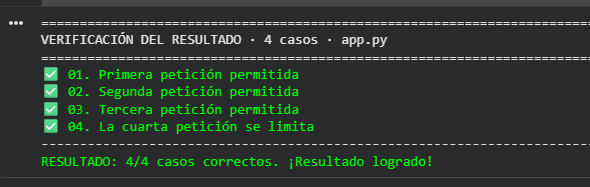